# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh, Evie McMahan, Zoe Edelblum

**Date:** 11/16/2026

In [15]:
# Your Phase 1 solution to the problem goes here.


# Question 1: Check out the data set `heart_failure` and appropriately clean it.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression

# Load the dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')

# Check the first few rows, missing values, and duplicates
print(df.head())
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.dtypes)

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

# Question 2: Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

Base Tree R2: -0.08449212275200102
Base Linear R2: 0.2648262172713174


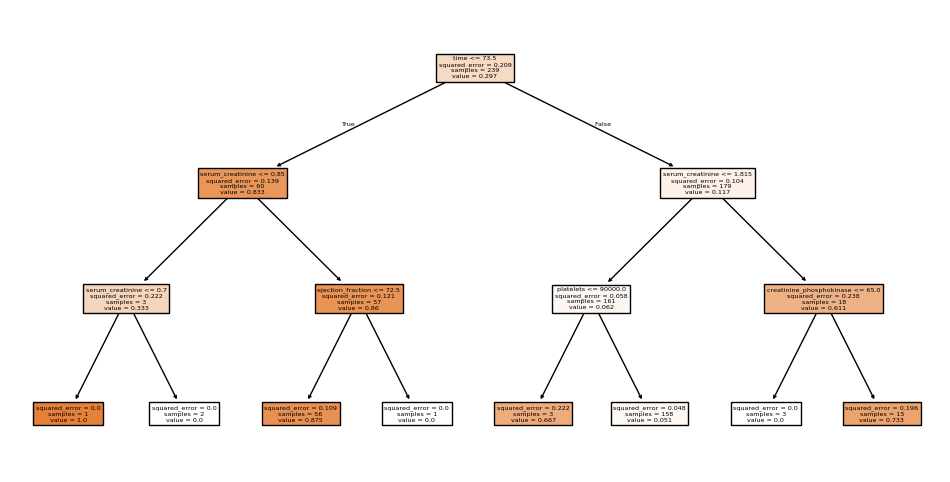

Base Linear Coefficients:
age                         6.304612e-03
anaemia                    -1.458543e-02
creatinine_phosphokinase    1.658588e-05
diabetes                    3.740270e-02
ejection_fraction          -9.021141e-03
high_blood_pressure        -2.203238e-02
platelets                  -6.360406e-08
serum_creatinine            1.071139e-01
serum_sodium               -5.683452e-03
sex                        -8.718761e-02
smoking                     1.729181e-02
time                       -2.672763e-03
dtype: float64


In [17]:
# separate features (X) and target (y)
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

# train test split with seed 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# fitting the tree and linear model
tree_base = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_base.fit(X_train, y_train)

lin_base = LinearRegression()
lin_base.fit(X_train, y_train)

# testing performance (R-squared score) on test data
print("Base Tree R2:", tree_base.score(X_test, y_test))
print("Base Linear R2:", lin_base.score(X_test, y_test))

# putting aside predictions on the base test set
pred_tree_base = tree_base.predict(X_test)
pred_lin_base = lin_base.predict(X_test)

# looks at the base tree and linear coefficients
plt.figure(figsize=(12, 6))
plot_tree(tree_base, feature_names=X.columns, filled=True)
plt.show()

print("Base Linear Coefficients:")
print(pd.Series(lin_base.coef_, index=X.columns))

# Question 3: Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients? Set aside the predictions these models make.

                          Base (42)  Seed 1  Seed 10  Seed 99
age                          0.0063  0.0050   0.0051   0.0061
anaemia                     -0.0146 -0.0119   0.0169  -0.0390
creatinine_phosphokinase     0.0000  0.0000   0.0000   0.0000
diabetes                     0.0374  0.0552   0.0403   0.0237
ejection_fraction           -0.0090 -0.0100  -0.0105  -0.0100
high_blood_pressure         -0.0220 -0.0419  -0.0160   0.0018
platelets                   -0.0000 -0.0000  -0.0000  -0.0000
serum_creatinine             0.1071  0.0907   0.1170   0.0882
serum_sodium                -0.0057 -0.0079  -0.0074  -0.0075
sex                         -0.0872 -0.0521  -0.0583  -0.0641
smoking                      0.0173 -0.0140  -0.0215   0.0162
time                        -0.0027 -0.0028  -0.0027  -0.0025


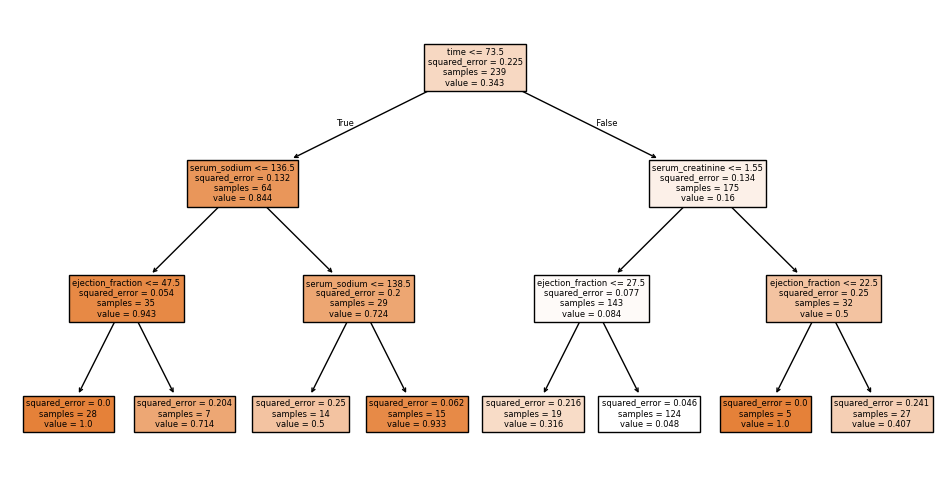

In [18]:
# puts all the linear coefficients side by side in one table
coef_table = pd.DataFrame({
    'Base (42)': lin_base.coef_,
    'Seed 1': lin_1.coef_,
    'Seed 10': lin_10.coef_,
    'Seed 99': lin_99.coef_
}, index=X.columns)

print(coef_table.round(4))

# plots seed 1's tree to compare visually with the base tree from step 2
plt.figure(figsize=(12, 6))
plot_tree(tree_1, feature_names=X.columns, filled=True)
plt.show()

**How Different are the Decision Trees?**

Across the different random train-test splits, the decision trees change quite a bit, especially once you look past the very top split. All four trees start by splitting on time at the top, though even that cutoff changes slightly and stays at time <= 73.50 for seeds 42, 1, and 10, and dropping to time <= 67.50 for seed 99. Once you go down to the second and third levels, the trees pick completely different variables and cutoff numbers. For example, on the left side (time <= 73.50), the base tree (seed=42) splits on serum_creatinine and ejection_fraction, while seeds 1 and 10 both switch to serum_sodium, and seed 99 switches to age. The same thing happens on the right side (time > 73.50), where the bottom splits bounce between platelets, creatinine_phosphokinase, ejection_fraction, and age depending on the seed. Because a decision tree builds branches one step at a time, changing a small portion of the training data can cause the tops to shift, which then changes all the branches underneath.

**How Different Are the Linear Model Coefficients?**

Unlike the decision trees, the linear model coefficients stay steady across all four random splits. The most important variables keep the same positive or negative signs and almost the exact same numbers every time. Time stays around -0.0025 to -0.0028, ejection_fraction stays around -0.0090 to -0.0105, serum_creatinine stays around +0.0882 to +0.1170, age stays around +0.0050 to +0.0063, and serum_sodium stays around -0.0057 to -0.0079. The only coefficients that flip signs are weak yes/no variables and those numbers are already super close to zero, like anaemia, high_blood_pressure, and smoking. Because a linear model uses all of the training data at once to fit one final line, swapping out a few training rows only slightly chanegs the numbers instead of changing the entire result.

# Question 4

# Question 5

# Question 6

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [19]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]